# Retail Analytics Warehouse — Metrics Report

Reads the dbt marts built in `warehouse.duckdb` (run `python scripts/load_raw.py && dbt build --profiles-dir .` first)
and reports weekly active households, basket economics, retention cohorts and data-quality results.

In [1]:
import duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt, pathlib, json
CH = pathlib.Path("charts"); CH.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
BLUE, GREY, RED = "#2563eb", "#9ca3af", "#dc2626"
con = duckdb.connect("warehouse.duckdb", read_only=True)
con.sql("select schema_name, table_name, estimated_size as rows from duckdb_tables() where schema_name = 'main_marts' order by 2").df()

,schema_name,table_name,rows
0,main_marts,dim_date,366
1,main_marts,dim_household,2469
2,main_marts,dim_product,92334
3,main_marts,fct_baskets,155518
4,main_marts,fct_sales,1460438
5,main_marts,mart_retention_cohorts,78
6,main_marts,mart_weekly_kpis,54


## 1. Data-quality results (from `dbt build`)

In [2]:
rr = json.load(open("target/run_results.json"))
tests = pd.DataFrame([{"test": r["unique_id"].split(".")[2], "status": r["status"]} for r in rr["results"] if r["unique_id"].startswith("test.")])
print(f"{len(tests)} data tests: {tests.status.value_counts().to_dict()}")
unknown = int(con.sql("select count(*) n from main_marts.dim_product where is_unknown_member").df().n[0])
print(f"Orphan product_ids in transactions added as UNKNOWN dimension members: {unknown}")
tests

24 data tests: {'pass': 24}
Orphan product_ids in transactions added as UNKNOWN dimension members: 3


,test,status
0,not_null_stg_households_household_id,pass
1,not_null_stg_products_product_id,pass
2,unique_stg_households_household_id,pass
3,accepted_values_stg_products_brand_type__Natio...,pass
4,unique_stg_products_product_id,pass
5,not_null_stg_transactions_basket_id,pass
6,not_null_stg_transactions_household_id,pass
7,not_null_stg_transactions_product_id,pass
8,not_null_stg_transactions_sales_value,pass
9,not_null_dim_date_date_day,pass


## 2. Weekly KPIs

Avg weekly active households 1334 of 2,469 (54%); avg basket $29.50; discount rate 15.1%


,week_start,weekly_active_households,baskets,sales,avg_basket_value,discount_rate
count,51,51.00,51.00,51.00,51.00,51.00
mean,2017-06-26 00:00:00,1334.33,2993.73,88361.53,29.50,0.15
min,2017-01-02 00:00:00,1279.00,2816.00,77394.97,26.16,0.13
25%,2017-03-30 12:00:00,1306.50,2921.00,84021.60,28.66,0.14
50%,2017-06-26 00:00:00,1331.00,2975.00,87469.41,29.21,0.15
75%,2017-09-21 12:00:00,1355.50,3052.00,91418.25,30.15,0.16
max,2017-12-18 00:00:00,1441.00,3429.00,115132.85,33.58,0.19
std,NaN,35.73,112.93,6030.89,1.33,0.01


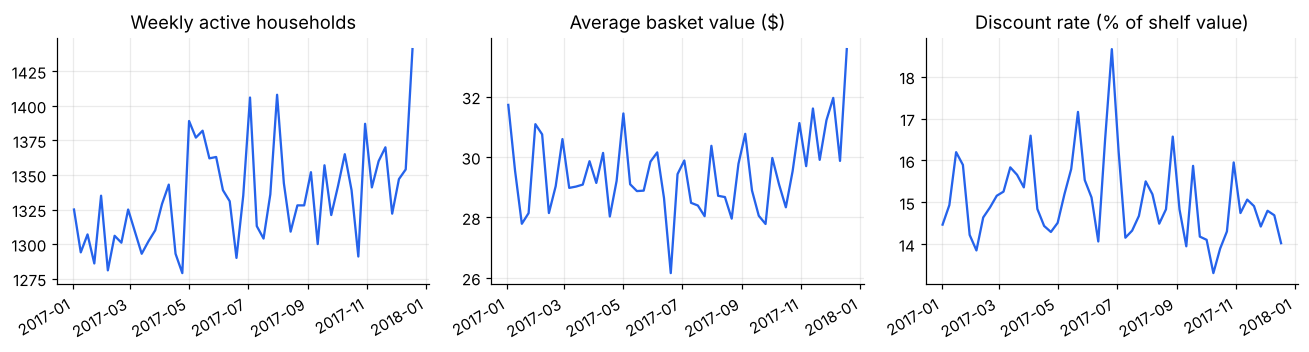

In [3]:
wk = con.sql("select * from main_marts.mart_weekly_kpis where week_start >= '2017-01-02' and week_start < '2017-12-25' order by 1").df()
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
ax[0].plot(wk.week_start, wk.weekly_active_households, color=BLUE); ax[0].set_title("Weekly active households")
ax[1].plot(wk.week_start, wk.avg_basket_value, color=BLUE); ax[1].set_title("Average basket value ($)")
ax[2].plot(wk.week_start, wk.discount_rate * 100, color=BLUE); ax[2].set_title("Discount rate (% of shelf value)")
fig.autofmt_xdate(); fig.tight_layout(); fig.savefig(CH / "01_weekly_kpis.png", bbox_inches="tight")
n_hh = int(con.sql("select count(*) n from main_marts.dim_household").df().n[0])
print(f"Avg weekly active households {wk.weekly_active_households.mean():.0f} of {n_hh:,} "
      f"({wk.weekly_active_households.mean()/n_hh:.0%}); avg basket ${wk.avg_basket_value.mean():.2f}; "
      f"discount rate {wk.discount_rate.mean():.1%}")
wk.describe().round(2)

## 3. Household engagement: stickiness and shopping frequency

In [4]:
eng = con.sql("""
with w as (select household_id, count(distinct date_trunc('week', basket_date)) wks, count(*) baskets, sum(basket_sales) sales
           from main_marts.fct_baskets group by 1)
select count(*) households, avg(wks) avg_active_weeks, median(baskets) median_baskets,
       avg((wks >= 26)::int) share_active_26plus_weeks,
       sum(sales) filter (where sales >= (select quantile_cont(sales, .8) from w)) / sum(sales) top20_sales_share
from w""").df()
eng.round(3)

,households,avg_active_weeks,median_baskets,share_active_26plus_weeks,top20_sales_share
0,2469,28.19,43.0,0.557,0.546


## 4. Retention cohorts

January cohort (1982 households): month-1 89%, month-6 90%, month-11 88%


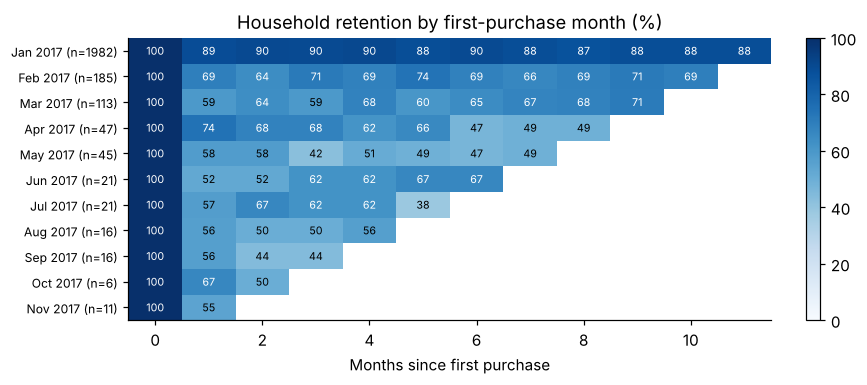

In [5]:
coh = con.sql("select * from main_marts.mart_retention_cohorts where cohort_month < '2017-12-01' order by 1, 2").df()
piv = coh.pivot(index="cohort_month", columns="months_since_first", values="retention")
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(piv.values * 100, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_yticks(range(len(piv))); ax.set_yticklabels([f"{d:%b %Y} (n={int(n)})" for d, n in zip(piv.index, coh[coh.months_since_first == 0].active_households)], fontsize=8)
ax.set_xlabel("Months since first purchase"); ax.set_title("Household retention by first-purchase month (%)"); ax.grid(False)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        if not np.isnan(v): ax.text(j, i, f"{v*100:.0f}", ha="center", va="center", fontsize=7, color="white" if v > .6 else "black")
fig.colorbar(im, fraction=.03); fig.tight_layout(); fig.savefig(CH / "02_retention_cohorts.png", bbox_inches="tight")
jan = piv.iloc[0]
print(f"January cohort ({int(coh.iloc[0].active_households)} households): month-1 {jan[1]:.0%}, month-6 {jan[6]:.0%}, month-11 {jan[11]:.0%}")

## 5. Campaign reach vs. spend (descriptive)

In [6]:
camp = con.sql("""
select h.campaigns_received >= 1 as got_campaign, count(*) households,
       avg(b.sales) avg_annual_sales, avg(b.baskets) avg_baskets
from main_marts.dim_household h
join (select household_id, sum(basket_sales) sales, count(*) baskets from main_marts.fct_baskets group by 1) b using (household_id)
group by 1 order by 1""").df()
camp.round(1)

,got_campaign,households,avg_annual_sales,avg_baskets
0,False,910,592.7,21.7
1,True,1559,2602.1,87.1


Campaign recipients spend more, but campaigns were targeted at engaged households, so this is **not** a causal effect —
a holdout design (see the email-lift project) is needed to measure incrementality.